# SpaNorm: spatially aware library size normalisation

This tutorial ports the R vignette of [SpaNorm](https://bhuvalab.github.io/SpaNorm) to Python with
`spanormpy`. SpaNorm removes library size effects from spatial molecular data while retaining biology:
it decomposes spatially smooth variation in a per-gene negative binomial model into a library-size
component and a biological component (thin plate splines), then adjusts the data using only the
biological part (percentile adjusted counts by default).

**Install**

```bash
pip install git+https://github.com/BhuvaLab/spanormpy   # for now
pip install spanormpy                                    # once published on PyPI
```

For a GPU, install the CUDA build of PyTorch first (see <https://pytorch.org>) and pass
`backend="gpu"` (or leave the default `backend="auto"`). This notebook uses `backend="cpu"` and
fits on 5% of the spots (`sample_p=0.05`) so that it runs in a few minutes on a laptop; the R vignette
uses the default `sample_p=0.25`.

## Load count data

We use a public 10x Visium dataset shipped with squidpy (adult mouse brain, ~2,700 spots, `sq.datasets.visium_hne_adata`),
so the notebook runs from a clean install (`pip install spanormpy squidpy`; the ~330 MB file is downloaded on first use).
SpaNorm needs **raw counts** (here `adata.raw`) and coordinates in `obsm["spatial"]`. Any other Visium `AnnData`
works the same way, for example one read with `scanpy.read_visium` or `squidpy.read.visium`.

The walk-through that is identical to the R vignette (human DLPFC, `HumanDLPFC`) is on the project website.

In [1]:
import warnings

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message=".*will be overwritten")  # re-running spanorm replaces logcounts
warnings.filterwarnings("ignore", message="IProgress not found")

import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import squidpy as sq

import spanormpy as sn

plt.rcParams.update({"figure.dpi": 80, "axes.grid": False})

cache_dir = Path(os.environ.get("SPANORMPY_CACHE", Path.home() / ".cache" / "spanormpy"))  # override with $SPANORMPY_CACHE
cache = cache_dir / "visium_hne_adata.h5ad"
full = sq.datasets.visium_hne_adata(path=cache)         # downloaded on first use
adata = full.raw.to_adata()                              # raw counts (sparse, integer-valued)
adata.obs = full.obs[["cluster"]].copy()
adata.obsm["spatial"] = full.obsm["spatial"]
adata.var = adata.var[[]]
adata.var_names_make_unique()
adata

AnnData object with n_obs × n_vars = 2688 × 18078
    obs: 'cluster'
    uns: 'cluster_colors', 'hvg', 'leiden', 'leiden_colors', 'neighbors', 'pca', 'rank_genes_groups', 'spatial', 'umap'
    obsm: 'X_pca', 'X_umap', 'spatial'
    obsp: 'connectivities', 'distances'
    layers: None (.X)

`filter_genes` flags genes expressed in at least `prop` of the spots (R `filterGenes`); with `inplace=False` it
returns the logical mask as R does. _Mobp_ is a marker of oligodendrocytes, which are enriched in white matter tracts.
To keep this tutorial quick on a CPU we keep the first 500 genes passing the filter plus _Mobp_.

In [2]:
gene = "Mobp"
keep = sn.filter_genes(adata, prop=0.2, inplace=False)
print(f"{keep.sum()} of {adata.n_vars} genes expressed in >= 20% of spots")
keep[adata.var_names.get_loc(gene)] = False         # make sure it is added exactly once below
sub = np.union1d(np.flatnonzero(keep)[:500], [adata.var_names.get_loc(gene)])
adata = adata[:, sub].copy()          # a real AnnData (copy), not a view
adata

9465 of 18078 genes expressed in >= 20% of spots


AnnData object with n_obs × n_vars = 2688 × 501
    obs: 'cluster'
    uns: 'cluster_colors', 'hvg', 'leiden', 'leiden_colors', 'neighbors', 'pca', 'rank_genes_groups', 'spatial', 'umap'
    obsm: 'X_pca', 'X_umap', 'spatial'
    obsp: 'connectivities', 'distances'
    layers: None (.X)

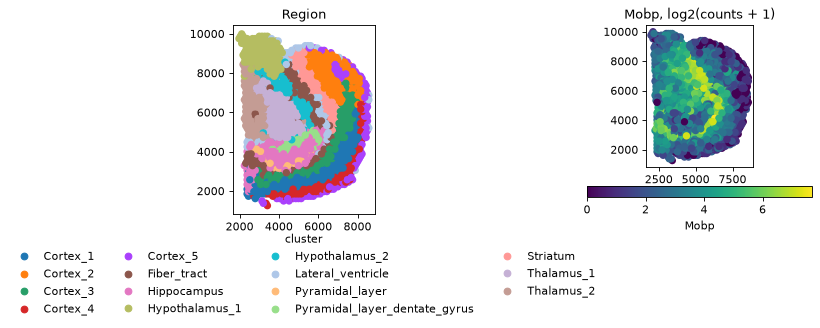

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4.25))
sn.pl.plot_spatial(adata, color="cluster", ax=ax[0], show=False)
ax[0].set_title("Region")
adata.layers["log2counts"] = np.log2(adata.X.toarray() + 1)
sn.pl.plot_spatial(adata, what="expression", color=gene, layer="log2counts", ax=ax[1], show=False)
ax[1].set_title("Mobp, log2(counts + 1)")
plt.tight_layout()

## Normalise count data

SpaNorm normalises in two steps: (1) fit the model of library size and biology on a subset of spots
(`sample_p`, default 0.25), (2) adjust the data with the fitted model. One call to `spanorm` does both.
It modifies `adata` in place: the normalised data go to `layers["logcounts"]`, and the fit is stored in
`var` / `varm` / `obsm` / `uns["spanorm"]` under the name `"spanorm"`. `random_state` replaces R's
`set.seed`.

The adjustment methods (`adj_method`) are `"logpac"` (percentile adjusted counts, default for
count data), `"pearson"`, `"meanbio"` and `"medbio"`.

In [4]:
sn.spanorm(adata, sample_p=0.05, backend="cpu", random_state=36, verbose=True)
adata

(1/2) Fitting SpaNorm model


134 cells/spots sampled to fit model
iter:  1, estimating gene-wise dispersion


iter:  1, log-likelihood: -99279.612348
iter:  1, fitting NB model
iter:  1, iter:  1, log-likelihood: -99279.612348
iter:  1, iter:  2, log-likelihood: -87170.716701
iter:  1, iter:  3, log-likelihood: -84946.388133
iter:  1, iter:  4, log-likelihood: -83638.465062
iter:  1, iter:  5, log-likelihood: -83219.974951
iter:  1, iter:  6, log-likelihood: -83017.591196
iter:  1, iter:  7, log-likelihood: -82956.006265
iter:  1, iter:  8, log-likelihood: -82910.086643
iter:  1, iter:  9, log-likelihood: -82901.846233 (converged)
iter:  2, estimating gene-wise dispersion


iter:  2, log-likelihood: -81200.633279
iter:  2, fitting NB model
iter:  2, iter:  1, log-likelihood: -81200.633279
iter:  2, iter:  2, log-likelihood: -80474.261879
iter:  2, iter:  2, log-likelihood: -80474.261879
iter:  2, iter:  2, log-likelihood: -80474.261879
iter:  2, iter:  3, log-likelihood: -80474.261879 (converged)
iter:  3, estimating gene-wise dispersion
iter:  3, log-likelihood: -80422.441786
iter:  3, fitting NB model
iter:  3, iter:  1, log-likelihood: -80422.441786


iter:  3, iter:  2, log-likelihood: -80369.401929
iter:  3, iter:  3, log-likelihood: -80305.598667
iter:  3, iter:  3, log-likelihood: -80305.598667
iter:  3, iter:  3, log-likelihood: -80305.598667
iter:  3, iter:  4, log-likelihood: -80305.598667 (converged)
iter:  4, estimating gene-wise dispersion
iter:  4, log-likelihood: -80295.047769
iter:  4, fitting NB model
iter:  4, iter:  1, log-likelihood: -80295.047769


iter:  4, iter:  2, log-likelihood: -80290.010164
iter:  4, iter:  3, log-likelihood: -80265.401175
iter:  4, iter:  3, log-likelihood: -80265.401175
iter:  4, iter:  3, log-likelihood: -80265.401175
iter:  4, iter:  4, log-likelihood: -80265.401175 (converged)
iter:  5, estimating gene-wise dispersion
iter:  5, log-likelihood: -80257.544706
iter:  5, fitting NB model
iter:  5, iter:  1, log-likelihood: -80257.544706
iter:  5, iter:  1, log-likelihood: -80257.544706


iter:  5, iter:  1, log-likelihood: -80257.544706
iter:  5, iter:  2, log-likelihood: -80257.544706
iter:  5, iter:  2, log-likelihood: -80257.544706
iter:  5, iter:  2, log-likelihood: -80257.544706
iter:  5, iter:  3, log-likelihood: -80257.544706 (converged)
iter:  6, log-likelihood: -80257.544706 (converged)
(2/2) Normalising data


AnnData object with n_obs × n_vars = 2688 × 501
    obs: 'cluster', 'spanorm_sampling', 'spanorm_size_factors'
    var: 'spanorm_gmean', 'spanorm_psi'
    uns: 'cluster_colors', 'hvg', 'leiden', 'leiden_colors', 'neighbors', 'pca', 'rank_genes_groups', 'spatial', 'umap', 'spanorm'
    obsm: 'X_pca', 'X_umap', 'spatial', 'spanorm_W'
    varm: 'spanorm_alpha'
    obsp: 'connectivities', 'distances'
    layers: None (.X), 'log2counts', 'logcounts'

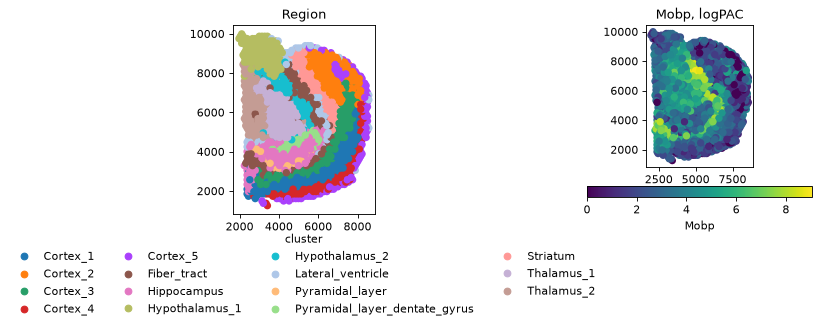

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4.25))
sn.pl.plot_spatial(adata, color="cluster", ax=ax[0], show=False)
ax[0].set_title("Region")
sn.pl.plot_spatial(adata, what="expression", color=gene, layer="logcounts", ax=ax[1], show=False)
ax[1].set_title("Mobp, logPAC")
plt.tight_layout()

## Scaling to large datasets

* `n_jobs` (R's `BPPARAM`) sets the number of CPU workers: `sn.spanorm(adata, n_jobs=4)`.
* `backend="gpu"` (or `"auto"`) uses CUDA (or Apple Metal, in float32). The GPU memory budget is
  detected automatically and genes are processed in blocks when they do not fit; override it with
  `spanormpy._backend.set_gpu_memory_budget(bytes)` or, for polishing, `sn.settings.polish_mem_budget`.
  See [benchmark.md](benchmark.md) for timings.
* Counts may be sparse (`scipy.sparse` CSR/CSC) in `X` or a layer (`layer=`); results equal the dense ones.

## Alternative adjustments from a stored fit

A valid stored fit is reused, so only the adjustment step runs. The fit is re-estimated when `overwrite=True`
or when `df_tps`, `lambda_a`, the batch specification or the object dimensions change. Subsetting genes
reuses the corresponding part of the fit, as R does after `subsetFitGenes`. Each call overwrites
`layers["logcounts"]`, so we copy the result of each method.

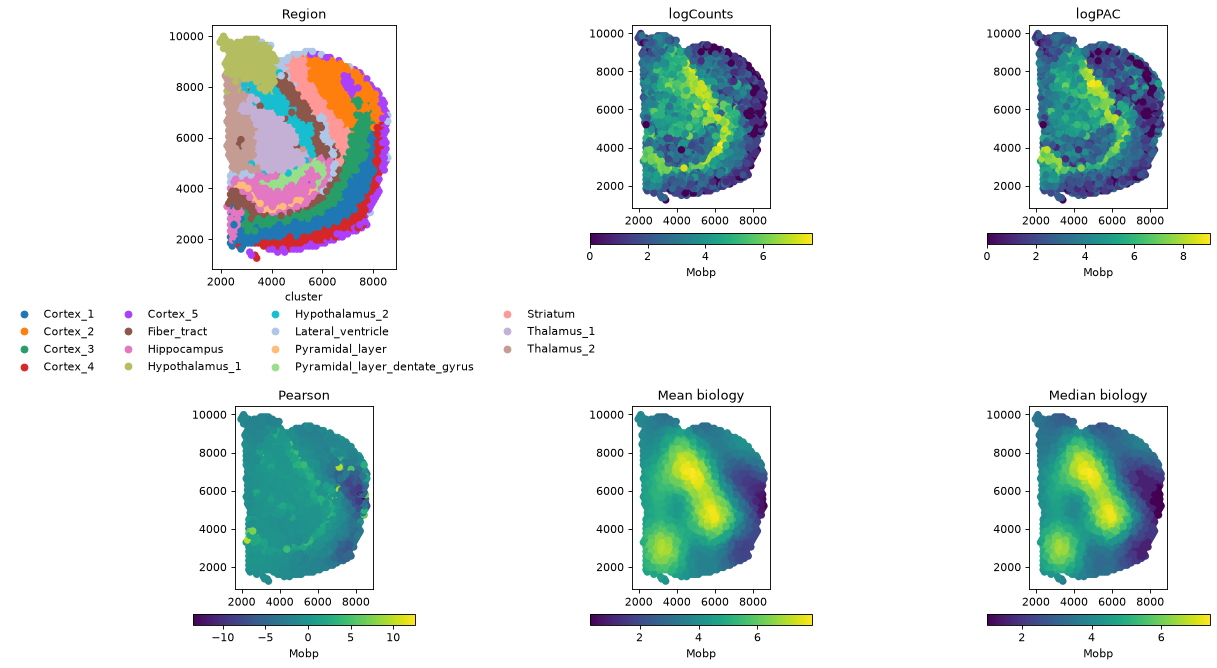

In [6]:
results = {"logPAC": adata.layers["logcounts"].copy()}
for label, method in [("Pearson", "pearson"), ("Mean biology", "meanbio"), ("Median biology", "medbio")]:
    sn.spanorm(adata, adj_method=method, backend="cpu", verbose=False)
    results[label] = adata.layers["logcounts"].copy()

fig, axes = plt.subplots(2, 3, figsize=(15, 8.5))
sn.pl.plot_spatial(adata, color="cluster", ax=axes[0, 0], show=False)
axes[0, 0].set_title("Region")
sn.pl.plot_spatial(adata, what="expression", color=gene, layer="log2counts", ax=axes[0, 1], show=False)
axes[0, 1].set_title("logCounts")
for ax, (label, mat) in zip(axes.ravel()[2:], results.items()):
    adata.layers["tmp"] = mat
    sn.pl.plot_spatial(adata, what="expression", color=gene, layer="tmp", ax=ax, show=False)
    ax.set_title(label)
del adata.layers["tmp"]
plt.tight_layout()

Compare how each adjustment recovers the spatial pattern of _Mobp_. Overall counts of this gene
are low in this sample, so noisy methods (Pearson, logPAC) are less smooth than the model-based means. Because the input counts are sparse, `logcounts` is sparse too.

## Varying model complexity

The complexity of the spatial smoothing functions is set by `df_tps` (default 6). Changing it triggers a
re-fit, so we work on a copy.

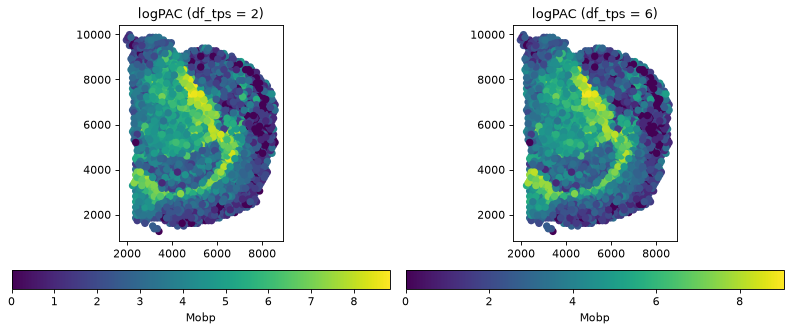

In [7]:
adata_df2 = adata.copy()
sn.spanorm(adata_df2, df_tps=2, sample_p=0.05, backend="cpu", random_state=36, verbose=False)
sn.spanorm(adata, adj_method="logpac", backend="cpu", verbose=False)   # back to logPAC, same fit

fig, ax = plt.subplots(1, 2, figsize=(10, 4.25))
sn.pl.plot_spatial(adata_df2, what="expression", color=gene, layer="logcounts", ax=ax[0], show=False)
ax[0].set_title("logPAC (df_tps = 2)")
sn.pl.plot_spatial(adata, what="expression", color=gene, layer="logcounts", ax=ax[1], show=False)
ax[1].set_title("logPAC (df_tps = 6)")
plt.tight_layout()

## Enhancing signal

Because there is a model for each gene, the signal of very low count genes can be raised by scaling all
adjusted means by a constant `scale_factor`.

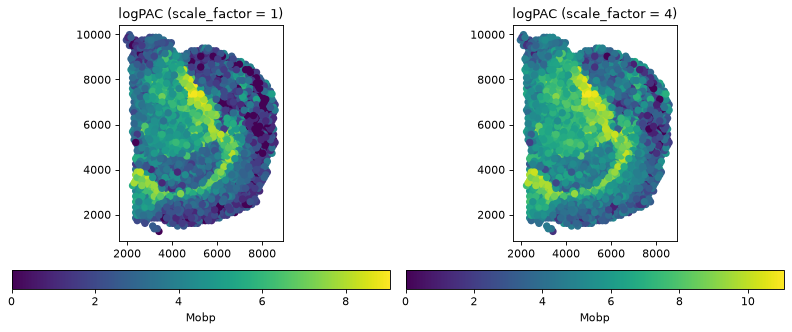

In [8]:
adata_sf4 = adata.copy()
sn.spanorm(adata_sf4, scale_factor=4, backend="cpu", verbose=False)

fig, ax = plt.subplots(1, 2, figsize=(10, 4.25))
sn.pl.plot_spatial(adata, what="expression", color=gene, layer="logcounts", ax=ax[0], show=False)
ax[0].set_title("logPAC (scale_factor = 1)")
sn.pl.plot_spatial(adata_sf4, what="expression", color=gene, layer="logcounts", ax=ax[1], show=False)
ax[1].set_title("logPAC (scale_factor = 4)")
plt.tight_layout()

## Exploring learnt functions

`sn.pl.plot_covariate` shows what the model learnt for a gene: the biology component or the library
size effect (`covariate="biology"` or `"ls"`; `"batch"` when a batch was given).

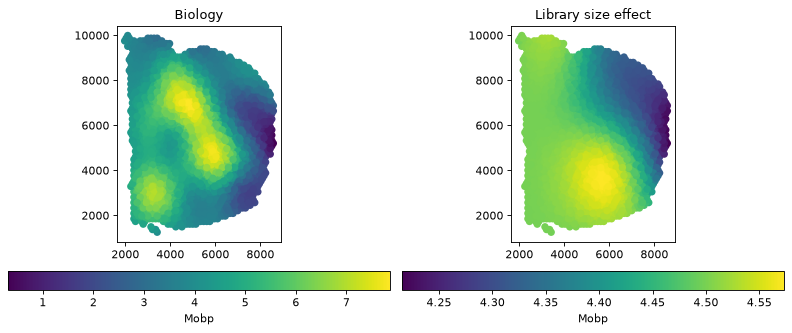

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4.25))
sn.pl.plot_covariate(adata, covariate="biology", color=gene, ax=ax[0], show=False)
ax[0].set_title("Biology")
sn.pl.plot_covariate(adata, covariate="ls", color=gene, ax=ax[1], show=False)
ax[1].set_title("Library size effect")
plt.tight_layout()

## Identifying spatially variable genes

`spanorm_svg` fits a nested model without the biological function

$$\log \mu_{c,g} = \varsigma_g + \{\alpha + h_g(x_c, y_c; \gamma_g)\}\, \log LS_c$$

and compares it with the full model per gene by an F-test. Results are written to `var["svg_F"]`,
`var["svg_p"]` and `var["svg_fdr"]`, and the null fit is stored as `spanorm_null`.

In [10]:
sn.spanorm_svg(adata, backend="cpu", verbose=False)
svgs = sn.top_svgs(adata, n=10)
svgs

,svg_F,svg_p,svg_fdr
Resp18,51.752061,7.521313e-275,3.768178e-272
3110035E14Rik,39.763908,2.815609e-218,7.053099e-216
Lypd1,37.558397,2.930444e-207,4.893841e-205
Ngef,36.997196,2.007709e-204,2.514656e-202
Mobp,34.623087,2.804057e-192,2.809665e-190
Zbtb18,34.594208,3.953868e-192,3.301480e-190
Dbi,33.583732,6.946482e-187,4.971697e-185
Scg2,29.025351,1.178694e-162,7.381570e-161
Rgs4,26.941044,2.954331e-151,1.644578e-149
Ogfrl1,26.519776,6.300408e-149,3.156504e-147


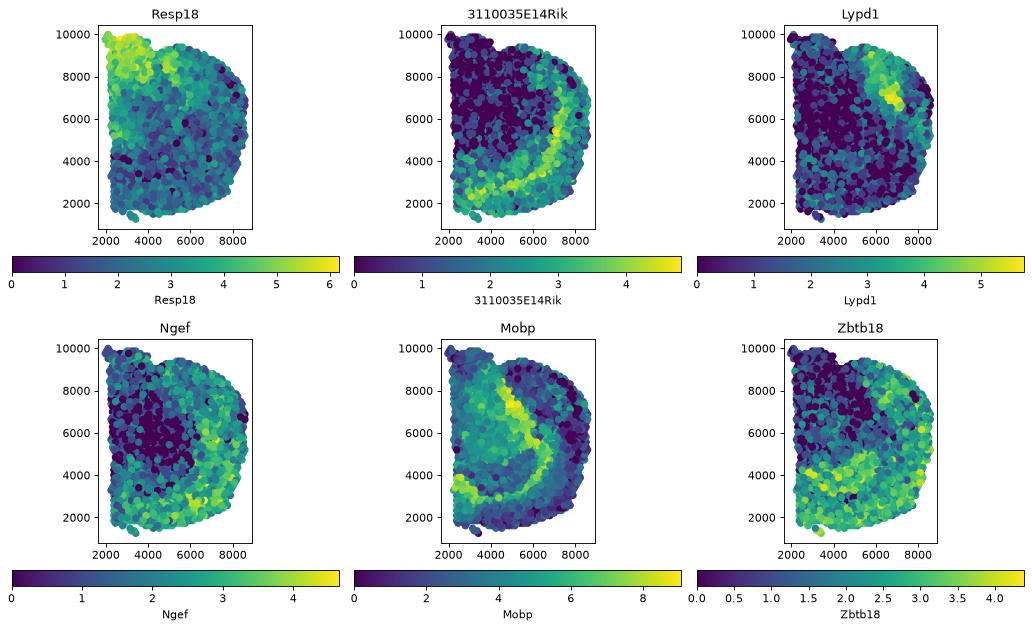

In [11]:
top = list(svgs.index[:6])
fig, axes = plt.subplots(2, 3, figsize=(13, 8))
for ax, g in zip(axes.ravel(), top):
    sn.pl.plot_spatial(adata, what="expression", color=g, layer="logcounts", ax=ax, show=False)
    ax.set_title(g)
plt.tight_layout()

## Polishing the fit

`spanorm` fits all genes in one shared IRLS loop. `polish_spanorm` then converges each gene separately
(damped Newton on its own penalised NB likelihood) and rewrites `logcounts` from the polished
coefficients; it matters mostly for bright, spatially restricted genes. If SVGs have been called it
re-polishes the null model and warns that the SVG statistics are stale (re-run `spanorm_svg`). Polishing is
slow on one CPU core and is shown but not run here:

```python
sn.polish_spanorm(adata, backend="gpu")   # or backend="cpu", n_jobs=8
```

`psi_method="fixed"` (default) keeps the dispersion estimated by `spanorm`; `"profile"` re-estimates it
by profile maximum likelihood. `ls="fixed"` (default) holds the shared library-size coefficient, `"joint"`
re-estimates it.

## GLM-PCA

PCA on log-transformed counts distorts low dimensional structure. `spanorm_pca` instead computes PCA on
deviance (or Pearson) residuals of the null model fit by `spanorm_svg`, restricted to the top SVGs. The
result goes to `obsm["X_spanorm_pca"]`, the convention scanpy uses for downstream neighbours and UMAP.

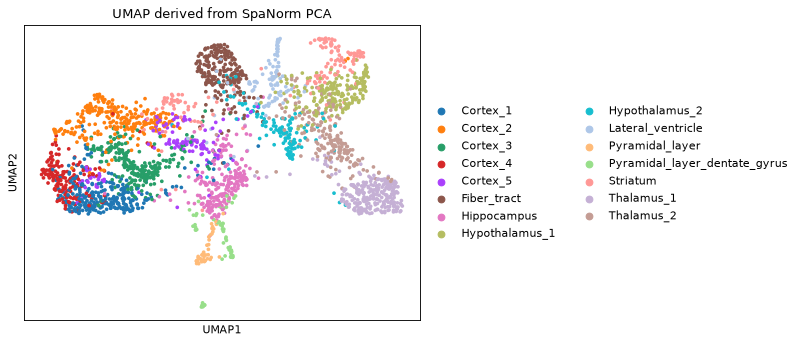

In [12]:
import scanpy as sc

sn.spanorm_pca(adata, ncomponents=20, nsvgs=500)  # R vignette: svg_fdr=0.2 on the full gene set
sc.pp.neighbors(adata, use_rep="X_spanorm_pca", n_neighbors=20)
sc.tl.umap(adata, min_dist=0.3, random_state=0)
sc.pl.umap(adata, color="cluster", title="UMAP derived from SpaNorm PCA")

## Fitting a custom model

The negative binomial engine is also available as a standalone per-gene GLM fitter, `fit_nb`. It fits
`log(mu) = W @ alpha.T` directly (no built-in intercept; include a column of ones).

In [13]:
rng = np.random.default_rng(1)
Y = rng.poisson(5, size=(20, 50)).astype(float)               # genes x cells, as in R
W = np.column_stack([np.ones(50), (np.arange(50) - 24.5) / np.std(np.arange(50), ddof=1)])
fit = sn.fit_nb(Y, W, backend="cpu", verbose=False)
fit["alpha"].shape, fit["psi"][:3]

((20, 2), array([0.00372586, 0.00061724, 0.00184694]))

## Differences from R and API map

* [r-to-python.md](r-to-python.md) maps every R export to its Python name.
* [r-discrepancies.md](r-discrepancies.md) lists intentional deviations.

## Session information

In [14]:
import platform, torch, scanpy
print("python", platform.python_version(), "| torch", torch.__version__, "| scanpy", scanpy.__version__,
      "| spanormpy", sn.__version__)

python 3.12.15 | torch 2.6.0+cu124 | scanpy 1.12.4 | spanormpy 0.1.0.dev0
